# CEMHSEY: cue-only control and false pinches

**Data.** CEMHSEY GESTURE (Yang et al., *Scientific Data* 12:1420, 2025), subject 1, days 1 and 2, five trials per day. Each 180 s trial cues eleven movements for 10 s each, separated by 5 s of rest. 320 HD-sEMG electrodes (five grids of 64, 2048 Hz). There is no force in GESTURE, so labels come from the cue schedule. The electrodes were taken off and put back on between days. The cue-only control also uses the Hyser random task (subject 1, trials 1 and 2).


In [21]:
import os
CEM_DIR = os.environ.get("CEM_DIR", r"C:\Users\karly\Hyser\GESTURE_S1\S1")
HYSER_DIR = os.environ.get("HYSER_DIR", r"C:\Users\karly\Hyser\random_dataset\subject01_session1")
CACHE_DIR = os.environ.get("CACHE_DIR", os.path.join("..", "..", "cemhsey_cache"))
FIG_DIR = os.environ.get("FIG_DIR", os.path.join("..", "figures"))
RES_DIR = os.environ.get("RES_DIR", os.path.join("..", "results"))
for directory in (CACHE_DIR, FIG_DIR, RES_DIR):
    CEM_DIR = os.environ.get("CEM_DIR", r"C:\Users\karly\Hyser\GESTURE_S1\S1")
    HYSER_DIR = os.environ.get("HYSER_DIR", r"C:\Users\karly\Hyser\random_dataset\subject01_session1")
    CACHE_DIR = os.environ.get("CACHE_DIR", os.path.join(os.path.expanduser("~"), "cemhsey_cache"))
    FIG_DIR = os.environ.get("FIG_DIR", os.path.join("..", "figures"))
    RES_DIR = os.environ.get("RES_DIR", os.path.join("..", "results"))

    for directory in (CACHE_DIR, FIG_DIR, RES_DIR):
        os.makedirs(directory, exist_ok=True)
SUBJECT, DAYS, TRIALS = 1, (1, 2), (1, 2, 3, 4, 5)

import json, struct, time, zlib, warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from IPython.display import Image, display
import os
warnings.filterwarnings("ignore")
%matplotlib inline

In [22]:
BLUE, ORANGE, INK, INK2, MUTED, GRIDLINE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#8c8b86", "#e4e3de"


def setup():
    import logging
    from matplotlib import font_manager as fm
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
    avail = {f.name for f in fm.fontManager.ttflist}
    fam = next((f for f in ["Calibri", "Carlito", "Segoe UI", "Arial"] if f in avail), "DejaVu Sans")
    plt.rcParams.update({
        "font.family": fam, "font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
        "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
        "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRIDLINE, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8,
        "lines.linewidth": 1.6, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
        "figure.facecolor": "white", "axes.facecolor": "white"})


def save(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path)
    plt.close(fig)
    display(Image(filename=path, width=900))
    print("saved", path)


setup()

## Protocol and labels

In [23]:
FS = 2048
GESTURES = ["hand close", "hand open", "wrist flexion", "wrist extension", "radial deviation", "ulnar deviation",
            "pronation", "supination", "2-finger pinch", "3-finger pinch", "lateral pinch"]
CUE = np.array([5 + 15 * k for k in range(11)], float)   # gesture k is cued from CUE[k] to CUE[k] + 10 s
WIN = 205 / FS                                            # 100 ms windows
PINCH, NONPINCH = 8, list(range(8))                       # 2-finger pinch; the eight non-pinch movements


def labels(nw, margin=1.0):
    """Label of each 100 ms window: gesture 0-10, -1 rest, -2 transition (not scored)."""
    t = (np.arange(nw) + 1) * WIN
    lab = np.full(nw, -1)
    for k, c in enumerate(CUE):
        lab[(t > c - 0.5) & (t <= c + margin)] = -2
        lab[(t > c + margin) & (t <= c + 10)] = k
        lab[(t > c + 10) & (t <= c + 10.8)] = -2
    lab[t <= 1.0] = -2
    return lab

## Reading the files

In [24]:
MI = {1: "i1", 2: "u1", 3: "i2", 4: "u2", 5: "i4", 6: "u4", 7: "f4", 9: "f8", 12: "i8", 13: "u8"}


def _tag(buf, off):
    t, n = struct.unpack_from("<II", buf, off)
    if t >> 16:
        return t & 0xFFFF, t >> 16, off + 4, off + 8
    return t, n, off + 8, off + 8 + n + (8 - n % 8) % 8


def read_mat_numpy(path):
    """numpy-only reader for the compressed MATLAB v5 files (used if scipy cannot read them)."""
    raw = open(path, "rb").read()
    t, n, d0, _ = _tag(raw, 128)
    el = zlib.decompress(raw[d0:d0 + n]) if t == 15 else raw[128:]
    del raw
    p = _tag(el, 0)[2]
    p = _tag(el, p)[3]
    dt, dn, d0b, p = _tag(el, p)
    dims = struct.unpack_from("<%di" % (dn // 4), el, d0b)
    p = _tag(el, p)[3]
    rt, rn, r0, p = _tag(el, p)
    arr = np.frombuffer(el, dtype="<" + MI[rt], count=rn // np.dtype(MI[rt]).itemsize, offset=r0)
    return arr.reshape(dims[1], dims[0])


def load_cemhsey(day, trial):
    """HD-sEMG of one trial, samples x 320 electrodes."""
    path = os.path.join(CEM_DIR, f"D{day}", f"S{SUBJECT}_Day{day}_Trial{trial}.mat")
    try:
        from scipy.io import loadmat
        return loadmat(path, variable_names=["data_sEMG"])["data_sEMG"].T
    except Exception:
        return read_mat_numpy(path)


def load_hyser_emg(n):
    """Hyser random task, raw HD-sEMG of trial n (WFDB format 16), samples x 256 electrodes."""
    stem = os.path.join(HYSER_DIR, f"random_raw_sample{n}")
    with open(stem + ".hea") as f:
        L = [l.split() for l in f if l.strip() and not l.startswith("#")]
    nsig, nsamp = int(L[0][1]), int(L[0][3])
    g = np.array([float(l[2].split("(")[0].split("/")[0]) for l in L[1:1 + nsig]])
    b = np.array([int(l[2].split("(")[1].split(")")[0]) if "(" in l[2] else 0 for l in L[1:1 + nsig]])
    d = np.fromfile(os.path.join(HYSER_DIR, L[1][0]), dtype="<i2").reshape(nsamp, nsig)
    return (d - b) / g

## Features

In [25]:
def emg_features(X):
    """Log RMS of each electrode in consecutive 100 ms windows, after removing a 25 ms trailing mean (causal)."""
    ns, nch = X.shape
    w, hpw = 205, 51
    nw = ns // w
    out = np.empty((nw, nch), np.float32)
    lo = np.clip(np.arange(ns) - hpw + 1, 0, None)
    for c0 in range(0, nch, 32):
        x = np.array(X[:, c0:c0 + 32], dtype=np.float64)
        cs = np.cumsum(np.vstack([np.zeros((1, x.shape[1])), x]), 0)
        hp = x - (cs[np.arange(ns) + 1] - cs[lo]) / (np.arange(ns) + 1 - lo)[:, None]
        out[:, c0:c0 + 32] = np.log(np.sqrt((hp[:nw * w] ** 2).reshape(nw, w, -1).mean(1)) + 1e-9)
    return out


def get_features(day, trial):
    f = os.path.join(CACHE_DIR, f"S{SUBJECT}_Day{day}_Trial{trial}.npz")
    if not os.path.exists(f):
        t0 = time.time()
        np.savez_compressed(f, logrms=emg_features(load_cemhsey(day, trial)))
        print(f"day {day} trial {trial}: features in {time.time() - t0:.0f} s")
    return np.load(f)["logrms"].astype(np.float64)


FEATS = {(d, t): get_features(d, t) for d in DAYS for t in TRIALS}
HYS = {n: emg_features(load_hyser_emg(n)).astype(np.float64) for n in (1, 2)}
print("CEMHSEY trials:", sorted(FEATS), "| Hyser trials:", sorted(HYS))

CEMHSEY trials: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5)] | Hyser trials: [1, 2]


## Figure 3 · Cue-only control

A model that only knows the time since the trial started: the average muscle activity (mean log RMS over electrodes, 100 ms windows) of four day-1 trials predicts the held-out day-1 trial and the five day-2 trials. On Hyser, which has no cues, trial 1 at the same elapsed time predicts trial 2 and the reverse. The level is matched to each predicted trial, so only the time course is compared.

In [26]:
def r2(p, y):
    return float(1 - np.sum((p - y) ** 2) / np.sum((y - y.mean()) ** 2))


def clock_only(template, y):
    n = min(len(template), len(y))
    return template[:n] - template[:n].mean() + y[:n].mean(), y[:n]


activity = lambda X: X.mean(1)
template = np.mean([activity(FEATS[(DAYS[0], t)]) for t in TRIALS[:-1]], 0)
CLOCK = {}
for d, t in [(DAYS[0], TRIALS[-1])] + [(DAYS[1], t) for t in TRIALS]:
    CLOCK[f"CEMHSEY day {d} trial {t}"] = r2(*clock_only(template, activity(FEATS[(d, t)])))
for a, b in ((1, 2), (2, 1)):
    CLOCK[f"Hyser trial {b} (from trial {a})"] = r2(*clock_only(activity(HYS[a]), activity(HYS[b])))
for k, v in CLOCK.items():
    print(f"{k:36s} R2 {v:+.2f}")

CEMHSEY day 1 trial 5                R2 +0.89
CEMHSEY day 2 trial 1                R2 +0.77
CEMHSEY day 2 trial 2                R2 +0.86
CEMHSEY day 2 trial 3                R2 +0.85
CEMHSEY day 2 trial 4                R2 +0.88
CEMHSEY day 2 trial 5                R2 +0.91
Hyser trial 2 (from trial 1)         R2 -0.03
Hyser trial 1 (from trial 2)         R2 -0.18


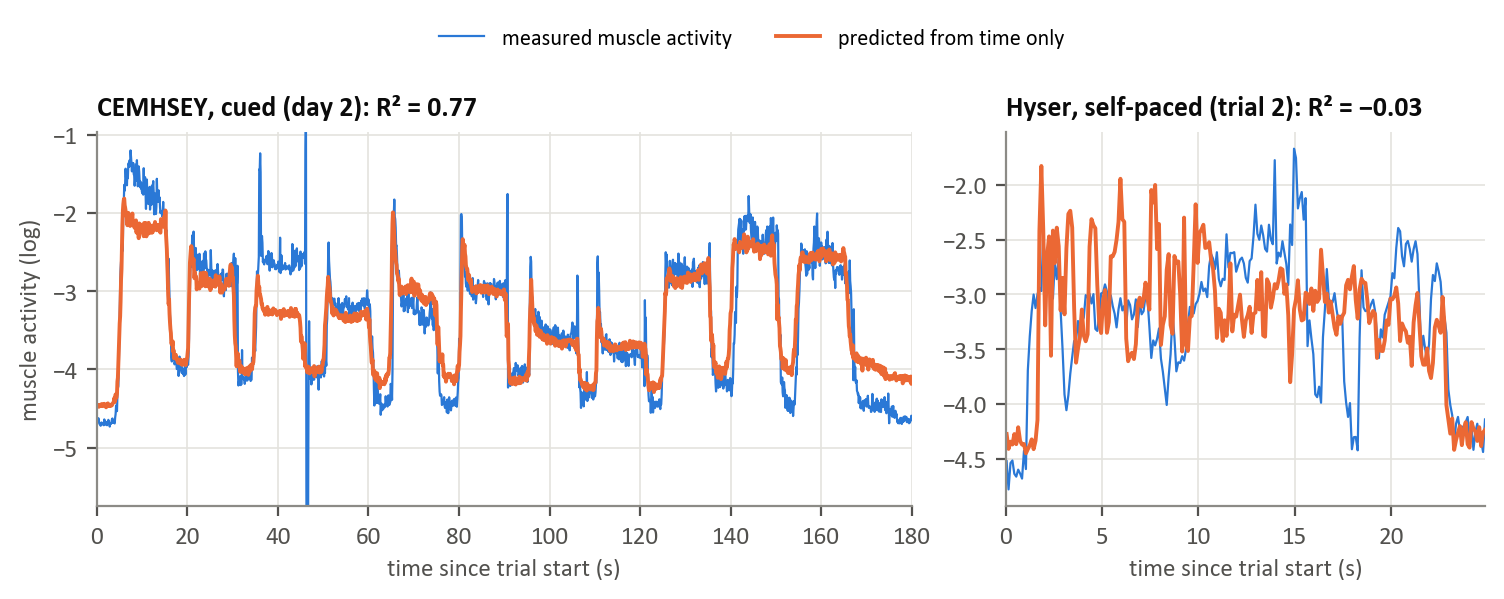

saved ..\figures\figure3.png


In [27]:
fig, axs = plt.subplots(1, 2, figsize=(7.6, 2.7), gridspec_kw=dict(width_ratios=[1.7, 1]))
ax = axs[0]
p, y = clock_only(template, activity(FEATS[(DAYS[1], 1)]))
t = (np.arange(len(y)) + 0.5) * WIN
ax.plot(t, y, color=BLUE, lw=0.8, label="measured muscle activity")
ax.plot(t, p, color=ORANGE, lw=1.4, label="predicted from time only")
ax.set_xlim(0, 180); ax.set_ylim(np.percentile(y, 0.2) - 0.3, np.percentile(y, 99.8) + 0.3)
ax.set_xlabel("time since trial start (s)"); ax.set_ylabel("muscle activity (log)")
ax.set_title(f"CEMHSEY, cued (day {DAYS[1]}): R\u00b2 = {r2(p, y):.2f}")
ax = axs[1]
p, y = clock_only(activity(HYS[1]), activity(HYS[2]))
t = (np.arange(len(y)) + 0.5) * WIN
ax.plot(t, y, color=BLUE, lw=0.8)
ax.plot(t, p, color=ORANGE, lw=1.4)
ax.set_xlim(0, t[-1]); ax.set_xlabel("time since trial start (s)")
ax.set_title("Hyser, self-paced (trial 2): R\u00b2 = " + f"{r2(p, y):.2f}".replace("-", "\u2212"))
fig.tight_layout(w_pad=1.2)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 1.0))
save(fig, "figure3.png")

## Figure 5 · False pinches

A 2-finger pinch detector calibrated on pinch and rest only: z-score with calibration statistics, 20 principal components, logistic regression, threshold 0.5. A pinch event needs at least three consecutive flagged windows (300 ms). Same day: calibrate on four trials of a day and test the fifth, every trial in turn. Other day: calibrate on all trials of one day and test every trial of the other day, in both directions, without any update.

In [28]:
class PinchDetector:
    def __init__(self, cal):
        X = np.vstack([FEATS[k] for k in cal])
        L = np.concatenate([labels(len(FEATS[k])) for k in cal])
        self.mu, self.sd = X[L == -1].mean(0), X.std(0) + 1e-9
        Z = (X - self.mu) / self.sd
        self.pca = PCA(n_components=20, random_state=0).fit(Z[L != -2])
        m = (L == PINCH) | (L == -1)
        self.clf = LogisticRegression(max_iter=3000).fit(self.pca.transform(Z[m]), (L[m] == PINCH).astype(int))

    def flags(self, k, threshold=0.5):
        return self.clf.predict_proba(self.pca.transform((FEATS[k] - self.mu) / self.sd))[:, 1] > threshold


def events(fl, k=3):
    """Number of runs of at least k consecutive flagged windows."""
    n, run = 0, 0
    for f in fl:
        run = run + 1 if f else 0
        n += run == k
    return n


share, rest_ev, rest_min, move_ev, move_min, same = {g: [] for g in [-1] + list(range(9))}, 0, 0.0, 0, 0.0, []
for d in DAYS:
    for t in TRIALS:
        fl = PinchDetector([(d, u) for u in TRIALS if u != t]).flags((d, t))
        L = labels(len(fl))
        for g in share:
            share[g].append(fl[L == g].mean())
        rest_ev += events(np.where(L == -1, fl, False)); rest_min += (L == -1).sum() * WIN / 60
        move_ev += sum(events(fl[L == g]) for g in NONPINCH); move_min += np.isin(L, NONPINCH).sum() * WIN / 60
        same.append(events(fl[L == PINCH]) > 0)
other = []
for a, b in ((DAYS[0], DAYS[1]), (DAYS[1], DAYS[0])):
    det = PinchDetector([(a, t) for t in TRIALS])
    for t in TRIALS:
        fl = det.flags((b, t))
        other.append(events(fl[labels(len(fl)) == PINCH]) > 0)
SHARE = {("rest" if g == -1 else GESTURES[g]): float(np.mean(v)) for g, v in share.items()}
for k, v in sorted(SHARE.items(), key=lambda kv: -kv[1]):
    print(f"{k:18s} time flagged as pinch {100 * v:5.1f}%")
print(f"false pinches per minute: rest {rest_ev / rest_min:.1f}, non-pinch movements {move_ev / move_min:.1f}")
print(f"pinches detected: same day {sum(same)}/{len(same)}, other day {sum(other)}/{len(other)}")

hand close         time flagged as pinch  99.4%
2-finger pinch     time flagged as pinch  99.2%
wrist extension    time flagged as pinch  79.4%
radial deviation   time flagged as pinch  50.1%
hand open          time flagged as pinch  45.3%
ulnar deviation    time flagged as pinch   9.7%
wrist flexion      time flagged as pinch   3.6%
pronation          time flagged as pinch   1.3%
supination         time flagged as pinch   0.7%
rest               time flagged as pinch   0.4%
false pinches per minute: rest 0.3, non-pinch movements 10.1
pinches detected: same day 10/10, other day 0/10


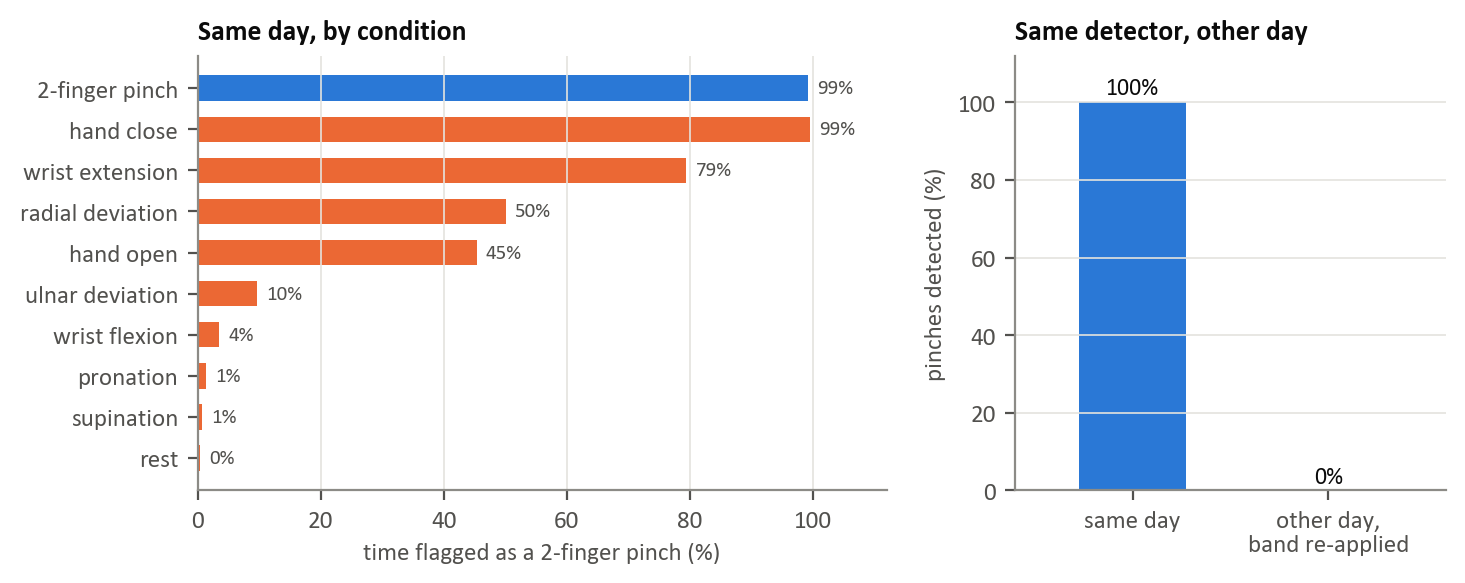

saved ..\figures\figure5.png


In [29]:
fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.0), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax = axs[0]
order = ["2-finger pinch"] + sorted([k for k in SHARE if k != "2-finger pinch"], key=lambda k: SHARE[k])[::-1]
y = np.arange(len(order))[::-1]
vals = [100 * SHARE[k] for k in order]
ax.barh(y, vals, height=0.62, color=[BLUE] + [ORANGE] * (len(order) - 1))
for yi, v in zip(y, vals):
    ax.text(v + 1.5, yi, f"{v:.0f}%", va="center", fontsize=7.5, color=INK2)
ax.set_yticks(y); ax.set_yticklabels(order); ax.set_xlim(0, 112); ax.grid(axis="y", visible=False)
ax.set_xlabel("time flagged as a 2-finger pinch (%)"); ax.set_title("Same day, by condition")
ax = axs[1]
v = [100 * np.mean(same), 100 * np.mean(other)]
ax.bar([0, 1], v, width=0.55, color=BLUE)
for xi, vi in zip([0, 1], v):
    ax.text(xi, vi + 2, f"{vi:.0f}%", ha="center", fontsize=8.5, color=INK)
ax.set_xticks([0, 1]); ax.set_xticklabels(["same day", "other day,\nband re-applied"]); ax.set_xlim(-0.6, 1.6)
ax.set_ylim(0, 112); ax.set_ylabel("pinches detected (%)"); ax.grid(axis="x", visible=False)
ax.set_title("Same detector, other day")
fig.tight_layout(w_pad=1.5)
save(fig, "figure5.png")

## Save the numbers

In [30]:
RES = dict(clock_only_r2=CLOCK, time_flagged_as_pinch=SHARE,
           false_pinches_per_min=dict(rest=rest_ev / rest_min, non_pinch_movements=move_ev / move_min),
           pinches_detected=dict(same_day=float(np.mean(same)), other_day=float(np.mean(other)), n=len(same)))
with open(os.path.join(RES_DIR, "cemhsey.json"), "w") as f:
    json.dump(RES, f, indent=1, default=float)
print("saved", os.path.join(RES_DIR, "cemhsey.json"))

saved ..\results\cemhsey.json
